---

# Baseline and Linear Models

*By Aryan.*

In this part we train a baseline, linear regression, ridge, lasso, and logistic regression.
We do both tasks: predicting `valence` (regression) and predicting whether a song is sad, meaning `valence < 0.3` (classification).
All tuning is done with 5-fold cross-validation on the training set. The test set is only used at the end.

This uses the cleaned features from `train_clean.csv`. We can rerun it once the engineered features are ready.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, lasso_path
from sklearn.model_selection import (KFold, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict, train_test_split)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
SAD_CUTOFF = 0.3

Loads the training set

In [2]:
train_df = pd.read_csv("train_clean.csv")

X = train_df.drop(columns=["valence"])
X["explicit"] = X["explicit"].astype(int)        
y = train_df["valence"]                           
y_sad = (y < SAD_CUTOFF).astype(int)            

print("X shape:", X.shape)
print(f"Share of sad songs: {y_sad.mean():.1%}")
X.head()

X shape: (63138, 14)
Share of sad songs: 31.0%


,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,tempo,time_signature,track_genre
0,151280,0,0.345,0.351,7,-7.844,1,0.0343,0.7130,0.000000,0.0876,96.538,4,club
1,440240,0,0.469,0.650,2,-9.220,0,0.0344,0.0450,0.001110,0.2310,123.929,4,goth
2,340141,0,0.622,0.459,6,-15.283,0,0.0449,0.0813,0.111000,0.1060,135.033,4,idm
3,307000,0,0.320,0.384,5,-10.710,1,0.0362,0.2960,0.000006,0.0805,119.353,4,gospel
4,191647,0,0.524,0.515,11,-7.478,0,0.0427,0.6740,0.000000,0.1040,169.882,4,pop


## 2. Preprocessing

Numeric columns are scaled with `StandardScaler`, since linear models (especially ridge and lasso) are sensitive to the scale of the features. It also lets us compare coefficients later.

`track_genre`, `key`, and `time_signature` are one-hot encoded. `key` and `time_signature` are stored as numbers, but they are really categories (key 11 is not "more" than key 2).

The preprocessing is put inside a `Pipeline` so that during cross-validation it is only fit on the training folds.

In [3]:
CAT_COLS = ["track_genre", "key", "time_signature"]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]
print("Numeric:", NUM_COLS)
print("Categorical:", CAT_COLS)

def make_preprocessor(num_cols, cat_cols, poly_degree=1):
    """Scale numeric columns (optionally add polynomial terms) and one-hot encode categorical ones."""
    num_steps = [("scale", StandardScaler())]
    if poly_degree > 1:
        num_steps.append(("poly", PolynomialFeatures(poly_degree, include_bias=False)))
    transformers = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
    return ColumnTransformer(transformers)

# The same folds are used for every model, so the scores are comparable.
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   

Numeric: ['duration_ms', 'explicit', 'danceability', 'energy', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'tempo']
Categorical: ['track_genre', 'key', 'time_signature']


### Results table

Two functions that score a model with 5-fold cross-validation and save the result in a table.

In [4]:
reg_results = []
clf_results = []

def eval_regressor(name, model, X_, y_=y, notes=""):
    """5-fold CV for a regression pipeline. Returns the scores and saves a row in reg_results."""
    s = cross_validate(model, X_, y_, cv=kf, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error",
                                "mae": "neg_mean_absolute_error", "r2": "r2"})
    row = {"model": name,
           "RMSE": -s["test_rmse"].mean(), "RMSE_std": s["test_rmse"].std(),
           "MAE": -s["test_mae"].mean(), "R2": s["test_r2"].mean(), "notes": notes}
    reg_results.append(row)
    print(f"{name}: RMSE {row['RMSE']:.4f} (+/- {row['RMSE_std']:.4f}), MAE {row['MAE']:.4f}, R2 {row['R2']:.4f}")
    return row

def eval_classifier(name, model, X_, y_=y_sad, threshold=0.5, notes=""):
    """5-fold CV for a classifier. Uses out-of-fold probabilities so we can apply any threshold."""
    proba = cross_val_predict(model, X_, y_, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    pred = (proba >= threshold).astype(int)
    row = {"model": name, "threshold": threshold,
           "F1": f1_score(y_, pred), "ROC_AUC": roc_auc_score(y_, proba),
           "accuracy": (pred == y_).mean(), "notes": notes}
    clf_results.append(row)
    print(f"{name}: F1 {row['F1']:.4f}, ROC-AUC {row['ROC_AUC']:.4f}, accuracy {row['accuracy']:.4f}")
    return row, proba

## 3. Baselines

For regression, the baseline always predicts the mean valence. For classification, the baseline always predicts "not sad".

In [5]:
eval_regressor("Baseline: predict mean", DummyRegressor(strategy="mean"), X);

Baseline: predict mean: RMSE 0.2621 (+/- 0.0008), MAE 0.2240, R2 -0.0000


In [6]:
eval_classifier("Baseline: always 'not sad'", DummyClassifier(strategy="most_frequent"), X);

Baseline: always 'not sad': F1 0.0000, ROC-AUC 0.5000, accuracy 0.6902


Predicting the mean gives an RMSE of about 0.26. Always guessing "not sad" is 69% accurate but has an F1 of 0, so we use F1 and ROC-AUC instead of accuracy.

## 4. Regression

### 4.1 Linear regression with and without genre

In [7]:
audio_cat = ["key", "time_signature"]
lin_audio = Pipeline([("pre", make_preprocessor(NUM_COLS, audio_cat)), ("model", LinearRegression())])
lin_full  = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS)),  ("model", LinearRegression())])

eval_regressor("Linear regression (audio only)", lin_audio, X, notes="no genre")
eval_regressor("Linear regression (audio + genre)", lin_full, X, notes="one-hot genre");

Linear regression (audio only): RMSE 0.2070 (+/- 0.0016), MAE 0.1689, R2 0.3762
Linear regression (audio + genre): RMSE 0.1842 (+/- 0.0009), MAE 0.1480, R2 0.5060


Adding genre raises R² from about 0.38 to 0.51, so we keep genre in all the models below.

### 4.2 Ridge and lasso

Ridge and lasso add a penalty on large coefficients, controlled by `alpha`. Lasso can also set coefficients to 0. We tune `alpha` with grid search.

In [8]:
ridge = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", Ridge())])
ridge_grid = GridSearchCV(ridge, {"model__alpha": np.logspace(-3, 4, 15)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X, y)
print("Best ridge alpha:", ridge_grid.best_params_["model__alpha"])

lasso = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", Lasso(max_iter=10000))])
lasso_grid = GridSearchCV(lasso, {"model__alpha": np.logspace(-6, -1, 11)},
                          cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X, y)
print("Best lasso alpha:", lasso_grid.best_params_["model__alpha"])

Best ridge alpha: 3.1622776601683795
Best lasso alpha: 1e-05


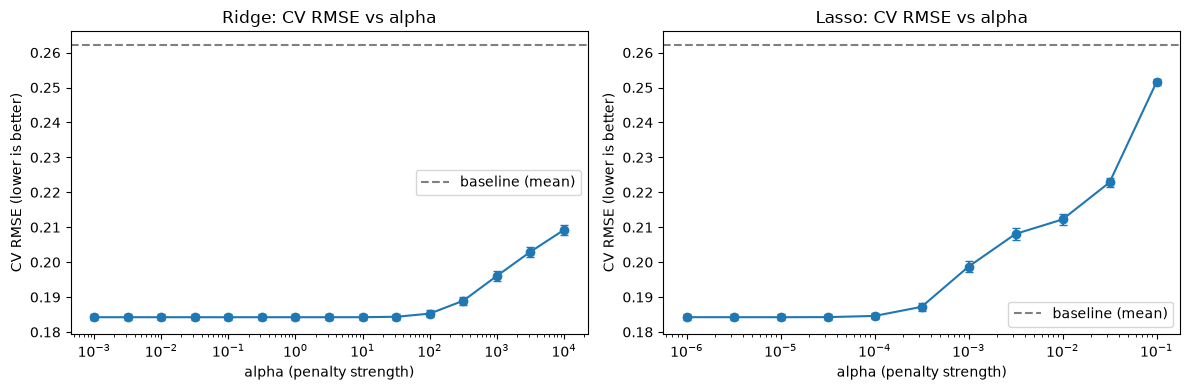

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grid, name in [(axes[0], ridge_grid, "Ridge"), (axes[1], lasso_grid, "Lasso")]:
    alphas = grid.cv_results_["param_model__alpha"].data.astype(float)
    mean_rmse = -grid.cv_results_["mean_test_score"]
    std_rmse = grid.cv_results_["std_test_score"]
    ax.errorbar(alphas, mean_rmse, yerr=std_rmse, marker="o", capsize=3)
    ax.axhline(reg_results[0]["RMSE"], color="gray", ls="--", label="baseline (mean)")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (penalty strength)")
    ax.set_ylabel("CV RMSE (lower is better)")
    ax.set_title(f"{name}: CV RMSE vs alpha")
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
eval_regressor("Ridge (tuned)", ridge_grid.best_estimator_, X,
               notes=f"alpha={ridge_grid.best_params_['model__alpha']:.3g}")
eval_regressor("Lasso (tuned)", lasso_grid.best_estimator_, X,
               notes=f"alpha={lasso_grid.best_params_['model__alpha']:.3g}");

Ridge (tuned): RMSE 0.1842 (+/- 0.0009), MAE 0.1481, R2 0.5060
Lasso (tuned): RMSE 0.1842 (+/- 0.0009), MAE 0.1481, R2 0.5061


Ridge and lasso score the same as plain linear regression, and a large alpha only makes things worse.
We have about 63,000 songs and 140 columns (11 numeric, 112 genres, 12 keys, 5 time signatures), so the model isn't overfitting and the penalty doesn't have much to fix.

### 4.3 Polynomial features

To let the model fit curves and interactions, we add squared and pairwise product terms for the 11 numeric columns. We don't do this for genre, since it would add thousands of columns.

In [11]:
ridge_poly = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS, poly_degree=2)), ("model", Ridge())])
ridge_poly_grid = GridSearchCV(ridge_poly, {"model__alpha": np.logspace(-2, 4, 13)},
                               cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_poly_grid.fit(X, y)
print("Best alpha:", ridge_poly_grid.best_params_["model__alpha"])

eval_regressor("Ridge + degree-2 polynomial (tuned)", ridge_poly_grid.best_estimator_, X,
               notes=f"alpha={ridge_poly_grid.best_params_['model__alpha']:.3g}");

Best alpha: 3.1622776601683795
Ridge + degree-2 polynomial (tuned): RMSE 0.1792 (+/- 0.0009), MAE 0.1432, R2 0.5327


This lowers RMSE from 0.184 to 0.179. So the relationship is not fully linear, which suggests the tree models may do better.

### 4.4 Lasso path

As alpha goes up, lasso sets more coefficients to 0. Features that stay in the longest are the most useful. We only use the numeric features here so the plot is readable.

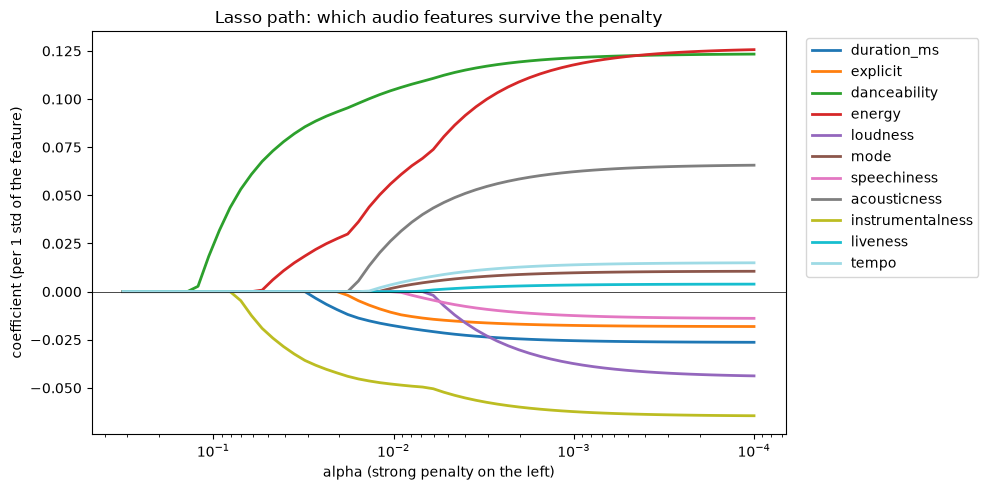

Features in the order lasso keeps them (first = most important):
  danceability      enters at alpha = 0.1215
  instrumentalness  enters at alpha = 0.0704
  energy            enters at alpha = 0.0536
  duration_ms       enters at alpha = 0.0271
  explicit          enters at alpha = 0.0180
  acousticness      enters at alpha = 0.0157
  tempo             enters at alpha = 0.0137
  mode              enters at alpha = 0.0119
  speechiness       enters at alpha = 0.0091
  liveness          enters at alpha = 0.0069
  loudness          enters at alpha = 0.0060


In [12]:
X_num_scaled = StandardScaler().fit_transform(X[NUM_COLS])
alphas_path, coefs_path, _ = lasso_path(X_num_scaled, y - y.mean(), alphas=np.logspace(-4, -0.5, 60))

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.tab20(np.linspace(0, 1, len(NUM_COLS)))   # 11 distinct colors
for i, col in enumerate(NUM_COLS):
    ax.plot(alphas_path, coefs_path[i], label=col, color=colors[i], lw=2)
ax.set_xscale("log")
ax.invert_xaxis()                       # left = strong penalty, right = weak penalty
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("alpha (strong penalty on the left)")
ax.set_ylabel("coefficient (per 1 std of the feature)")
ax.set_title("Lasso path: which audio features survive the penalty")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Order in which features first become non-zero (as the penalty gets weaker)
first_alpha = {col: (alphas_path[np.nonzero(coefs_path[i])[0][0]] if np.any(coefs_path[i]) else 0)
               for i, col in enumerate(NUM_COLS)}
print("Features in the order lasso keeps them (first = most important):")
for col, a in sorted(first_alpha.items(), key=lambda kv: -kv[1]):
    print(f"  {col:17s} enters at alpha = {a:.4f}")

Danceability is kept first, then instrumentalness, then energy. Mode (major/minor) comes in late with a small coefficient.

Acousticness and loudness flip sign compared to their simple correlations with valence. This is because they are strongly correlated with energy. Once energy is in the model, their coefficients only describe what's left over, so we shouldn't read them on their own.

### 4.5 Regression results (cross-validation)

In [13]:
pd.DataFrame(reg_results).round(4)

,model,RMSE,RMSE_std,MAE,R2,notes
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,
1,Linear regression (audio only),0.2070,0.0016,0.1689,0.3762,no genre
2,Linear regression (audio + genre),0.1842,0.0009,0.1480,0.5060,one-hot genre
3,Ridge (tuned),0.1842,0.0009,0.1481,0.5060,alpha=3.16
4,Lasso (tuned),0.1842,0.0009,0.1481,0.5061,alpha=1e-05
5,Ridge + degree-2 polynomial (tuned),0.1792,0.0009,0.1432,0.5327,alpha=3.16


## 5. Classification

### 5.1 Logistic regression

We tune `C` (smaller C means a stronger penalty) and `class_weight`. Since only 31% of songs are sad, `class_weight="balanced"` makes mistakes on sad songs count more. We score with ROC-AUC.

In [14]:
logreg = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS)), ("model", LogisticRegression(max_iter=3000))])
logreg_grid = GridSearchCV(logreg,
                           {"model__C": np.logspace(-3, 2, 6),
                            "model__class_weight": [None, "balanced"]},
                           cv=skf, scoring="roc_auc", n_jobs=-1)
logreg_grid.fit(X, y_sad)
print("Best settings:", logreg_grid.best_params_)
print(f"Best CV ROC-AUC: {logreg_grid.best_score_:.4f}")

Best settings: {'model__C': np.float64(1.0), 'model__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8626


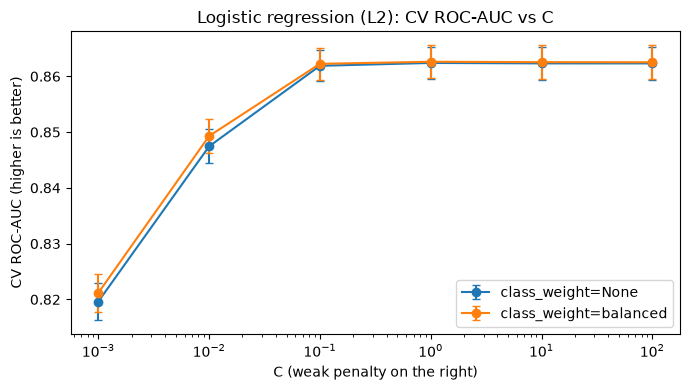

In [15]:
cv = pd.DataFrame(logreg_grid.cv_results_)
cv["class_weight"] = cv["param_model__class_weight"].map(lambda v: "balanced" if v == "balanced" else "None")
fig, ax = plt.subplots(figsize=(7, 4))
for cw, g in cv.groupby("class_weight"):
    ax.errorbar(g["param_model__C"].astype(float), g["mean_test_score"], yerr=g["std_test_score"],
                marker="o", capsize=3, label=f"class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (weak penalty on the right)")
ax.set_ylabel("CV ROC-AUC (higher is better)")
ax.set_title("Logistic regression (L2): CV ROC-AUC vs C")
ax.legend()
plt.tight_layout()
plt.show()

ROC-AUC levels off around C = 0.1. Class weight barely changes ROC-AUC, since ROC-AUC only depends on how songs are ranked, not on the threshold.

### 5.2 Choosing the threshold

We pick the threshold that gives the best F1, using out-of-fold predictions on the training set.

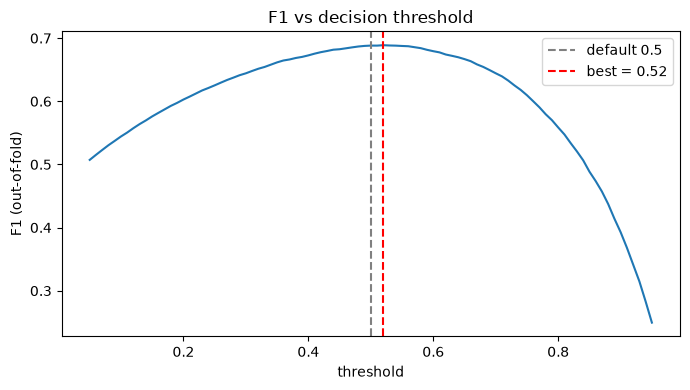

Best threshold: 0.52, F1 = 0.6888 (vs. 0.6882 at 0.5)


In [16]:
best_logreg = logreg_grid.best_estimator_
oof_proba = cross_val_predict(best_logreg, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
f1s = [f1_score(y_sad, (oof_proba >= t).astype(int)) for t in thresholds]
best_t = round(float(thresholds[int(np.argmax(f1s))]), 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, f1s)
ax.axvline(0.5, color="gray", ls="--", label="default 0.5")
ax.axvline(best_t, color="red", ls="--", label=f"best = {best_t:.2f}")
ax.set_xlabel("threshold")
ax.set_ylabel("F1 (out-of-fold)")
ax.set_title("F1 vs decision threshold")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Best threshold: {best_t:.2f}, F1 = {max(f1s):.4f} (vs. {f1_score(y_sad, (oof_proba >= 0.5).astype(int)):.4f} at 0.5)")

In [17]:
cw_note = f"C={logreg_grid.best_params_['model__C']:.3g}, class_weight={logreg_grid.best_params_['model__class_weight']}"
eval_classifier("Logistic regression (tuned, threshold 0.5)", best_logreg, X, threshold=0.5, notes=cw_note)
eval_classifier(f"Logistic regression (tuned, threshold {best_t:.2f})", best_logreg, X, threshold=best_t, notes=cw_note);

Logistic regression (tuned, threshold 0.5): F1 0.6882, ROC-AUC 0.8626, accuracy 0.7809
Logistic regression (tuned, threshold 0.52): F1 0.6888, ROC-AUC 0.8626, accuracy 0.7860


The best threshold is close to 0.5 because the balanced class weights already make up for the imbalance. As a check, the same search without class weights:

In [18]:
unweighted = Pipeline([("pre", make_preprocessor(NUM_COLS, CAT_COLS)),
                       ("model", LogisticRegression(C=logreg_grid.best_params_["model__C"], max_iter=3000))])
oof_unw = cross_val_predict(unweighted, X, y_sad, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
f1s_unw = [f1_score(y_sad, (oof_unw >= t).astype(int)) for t in thresholds]
best_t_unw = round(float(thresholds[int(np.argmax(f1s_unw))]), 2)
print(f"No class weights, threshold 0.50: F1 = {f1_score(y_sad, (oof_unw >= 0.5).astype(int)):.4f}")
print(f"No class weights, best threshold {best_t_unw:.2f}: F1 = {max(f1s_unw):.4f}")

No class weights, threshold 0.50: F1 = 0.6482
No class weights, best threshold 0.31: F1 = 0.6885


Without class weights, F1 at 0.5 is lower, but moving the threshold down to about 0.3 gets the same F1 as the balanced model. Both approaches fix the same problem.

The threshold was picked on the same predictions it's scored on, so that F1 is a little optimistic. The test set gives the real number.

### 5.3 Confusion matrix, ROC and precision-recall curves

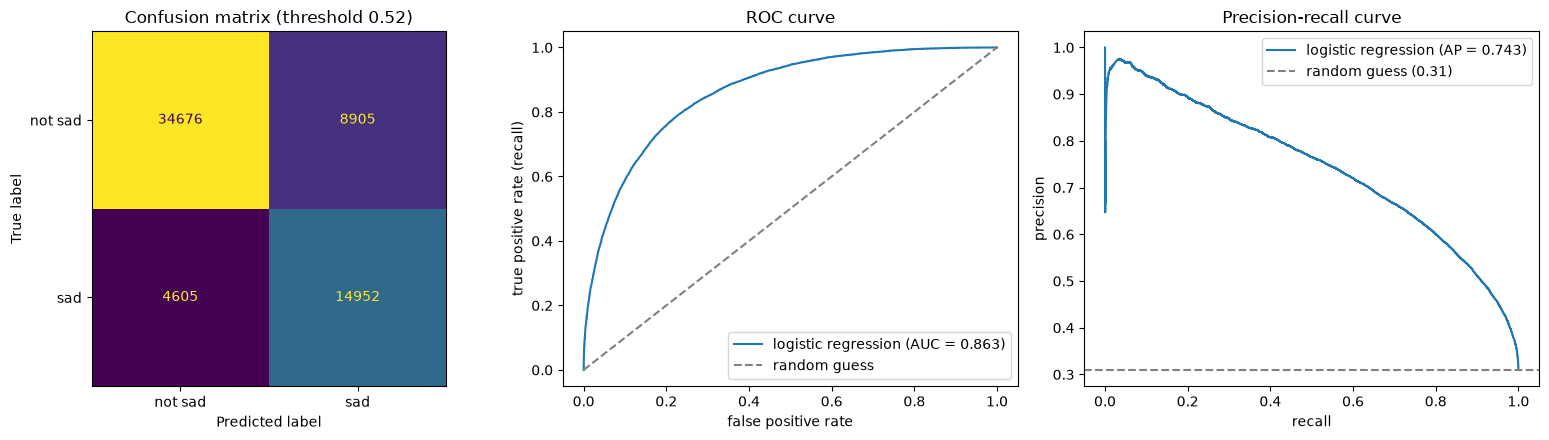

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_sad, (oof_proba >= best_t).astype(int)),
                       display_labels=["not sad", "sad"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix (threshold {best_t:.2f})")

fpr, tpr, _ = roc_curve(y_sad, oof_proba)
axes[1].plot(fpr, tpr, label=f"logistic regression (AUC = {roc_auc_score(y_sad, oof_proba):.3f})")
axes[1].plot([0, 1], [0, 1], color="gray", ls="--", label="random guess")
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()

prec, rec, _ = precision_recall_curve(y_sad, oof_proba)
axes[2].plot(rec, prec, label=f"logistic regression (AP = {average_precision_score(y_sad, oof_proba):.3f})")
axes[2].axhline(y_sad.mean(), color="gray", ls="--", label=f"random guess ({y_sad.mean():.2f})")
axes[2].set_xlabel("recall")
axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curve")
axes[2].legend()

plt.tight_layout()
plt.show()

### 5.4 Classification results (cross-validation)

In [20]:
pd.DataFrame(clf_results).round(4)

,model,threshold,F1,ROC_AUC,accuracy,notes
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6882,0.8626,0.7809,"C=1, class_weight=balanced"
2,"Logistic regression (tuned, threshold 0.52)",0.52,0.6888,0.8626,0.7860,"C=1, class_weight=balanced"


## 6. Interpreting the models

### 6.1 Ridge coefficients

The numeric features are scaled, so each coefficient is the change in valence for a one standard deviation increase.

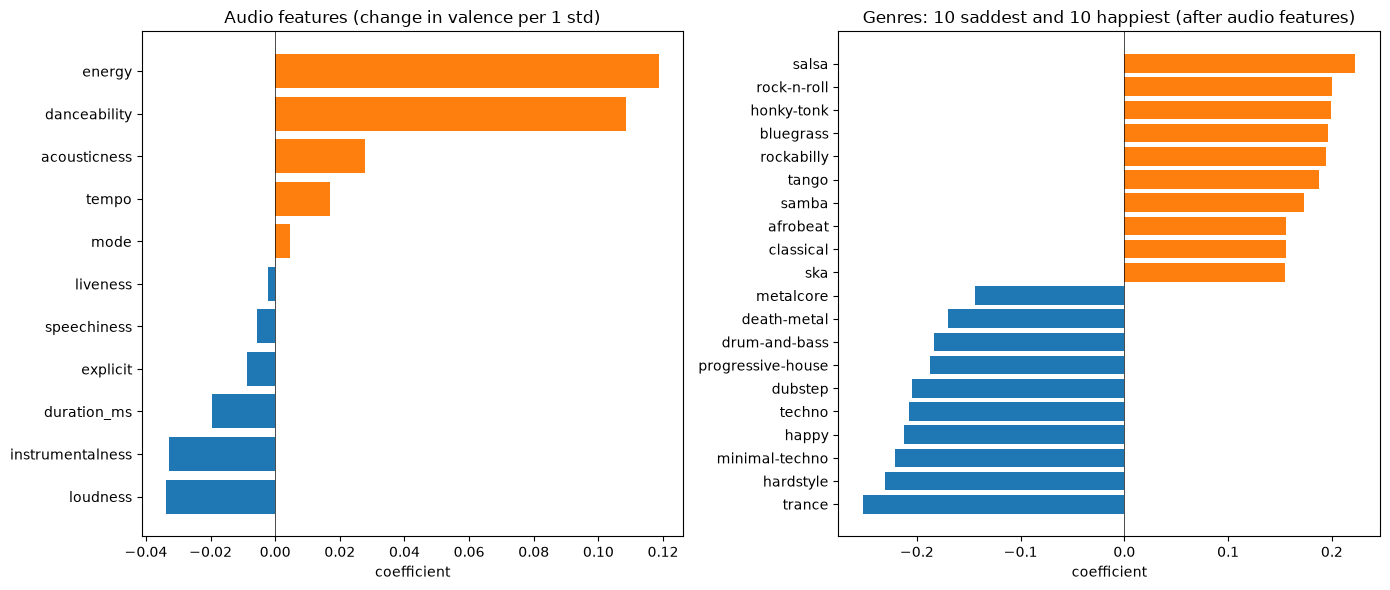

In [21]:
ridge_best = ridge_grid.best_estimator_.fit(X, y)
names = ridge_best.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(ridge_best.named_steps["model"].coef_, index=names)

num_coefs = coefs[[n.startswith("num__") for n in names]].rename(lambda n: n.replace("num__", "")).sort_values()
genre_coefs = coefs[[n.startswith("cat__track_genre_") for n in names]].rename(lambda n: n.replace("cat__track_genre_", "")).sort_values()
genre_show = pd.concat([genre_coefs.head(10), genre_coefs.tail(10)])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(num_coefs.index, num_coefs.values, color=np.where(num_coefs.values < 0, "tab:blue", "tab:orange"))
axes[0].axvline(0, color="black", lw=0.5)
axes[0].set_title("Audio features (change in valence per 1 std)")
axes[0].set_xlabel("coefficient")
axes[1].barh(genre_show.index, genre_show.values, color=np.where(genre_show.values < 0, "tab:blue", "tab:orange"))
axes[1].axvline(0, color="black", lw=0.5)
axes[1].set_title("Genres: 10 saddest and 10 happiest (after audio features)")
axes[1].set_xlabel("coefficient")
plt.tight_layout()
plt.show()

Energy and danceability have the largest positive coefficients. Loudness and instrumentalness are the most negative. Mode is close to 0.

The genre coefficients are adjustments on top of the audio features. For example, trance and techno songs are energetic and danceable, so the audio features predict a high valence, but their actual valence is lower, so they get negative coefficients. The same thing happens to the "happy" genre. Classical goes the other way: it's quiet, so the audio predicts low valence, but it's a little higher than that.

### 6.2 Permutation importance

We shuffle one column at a time and see how much the RMSE goes up on a validation set (20% of the training set). Genre is shuffled as one column.

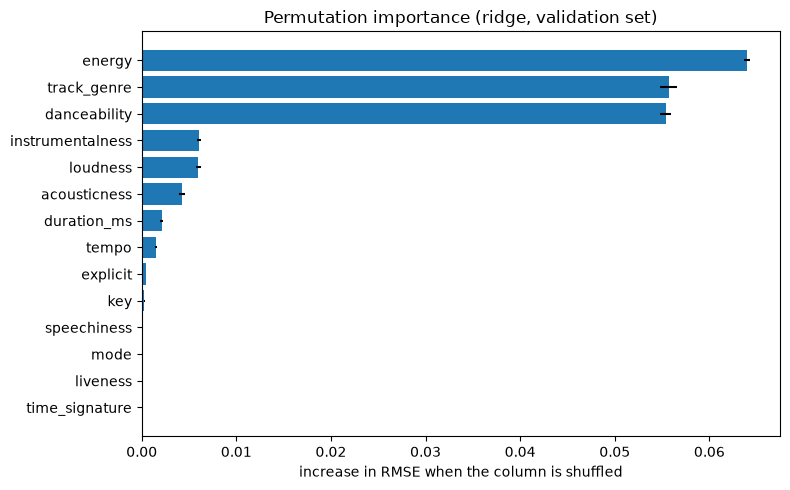

,increase_in_RMSE,std
energy,0.0639,0.0003
track_genre,0.0557,0.0009
danceability,0.0554,0.0006
instrumentalness,0.0060,0.0002
loudness,0.0060,0.0002
acousticness,0.0043,0.0003
duration_ms,0.0021,0.0001
tempo,0.0015,0.0001
explicit,0.0004,0.0000
key,0.0003,0.0000


In [22]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
perm_model = ridge_grid.best_estimator_.fit(X_tr, y_tr)
perm = permutation_importance(perm_model, X_val, y_val, scoring="neg_root_mean_squared_error",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.DataFrame({"increase_in_RMSE": perm.importances_mean, "std": perm.importances_std},
                        index=X.columns).sort_values("increase_in_RMSE")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(perm_imp.index, perm_imp["increase_in_RMSE"], xerr=perm_imp["std"])
ax.set_xlabel("increase in RMSE when the column is shuffled")
ax.set_title("Permutation importance (ridge, validation set)")
plt.tight_layout()
plt.show()
perm_imp.sort_values("increase_in_RMSE", ascending=False).round(4)

Energy, genre, and danceability matter the most. Mode, liveness, and time signature add almost nothing.

Energy ranks higher here than in the lasso path because the lasso path didn't include genre.

### 6.3 Error analysis

We look at out-of-fold predictions from the polynomial ridge model. Residual = predicted − true.

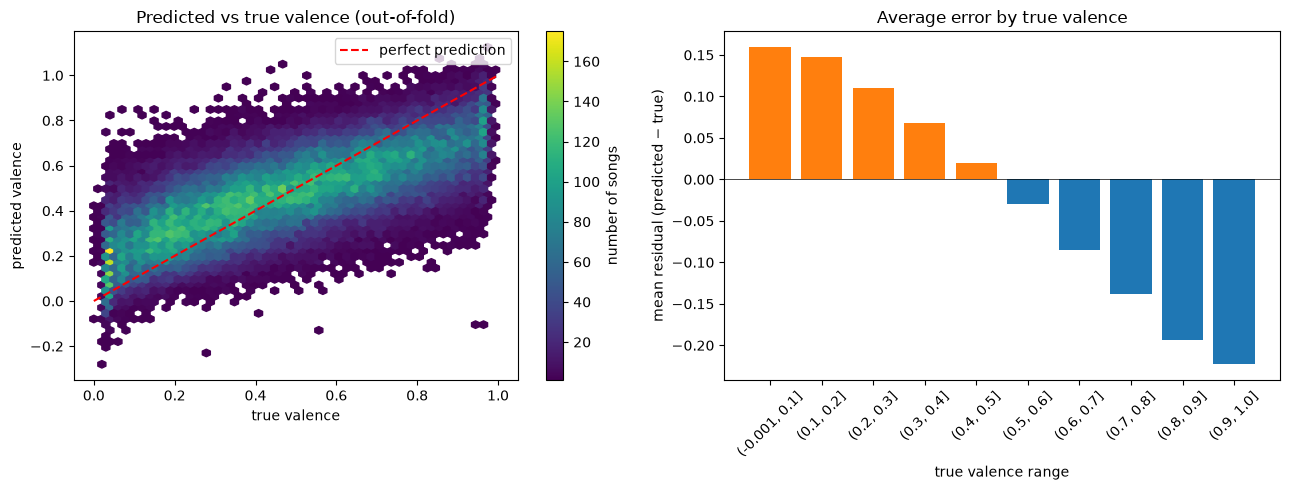

In [23]:
best_reg = ridge_poly_grid.best_estimator_
oof_pred = cross_val_predict(best_reg, X, y, cv=kf, n_jobs=-1)
resid = oof_pred - y

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
hb = axes[0].hexbin(y, oof_pred, gridsize=50, cmap="viridis", mincnt=1)
axes[0].plot([0, 1], [0, 1], color="red", ls="--", label="perfect prediction")
axes[0].set_xlabel("true valence")
axes[0].set_ylabel("predicted valence")
axes[0].set_title("Predicted vs true valence (out-of-fold)")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="number of songs")

bins = pd.cut(y, np.arange(0, 1.01, 0.1), include_lowest=True)
by_bin = resid.groupby(bins, observed=True).mean()
axes[1].bar([str(b) for b in by_bin.index], by_bin.values,
            color=np.where(by_bin.values > 0, "tab:orange", "tab:blue"))
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_xlabel("true valence range")
axes[1].set_ylabel("mean residual (predicted − true)")
axes[1].set_title("Average error by true valence")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

The model pulls its predictions toward the middle: the saddest songs are predicted too happy and the happiest songs too sad.

Low valence can mean sad and calm, or dark and intense (like metal). We compare the error for these two groups.

In [24]:
low = y < SAD_CUTOFF
groups = {
    "low valence, low energy (< 0.4)  ~ sad/calm": low & (X["energy"] < 0.4),
    "low valence, high energy (> 0.7) ~ angry/intense": low & (X["energy"] > 0.7),
    "all other songs": ~low,
}
error_by_group = pd.DataFrame({
    name: {"songs": int(mask.sum()),
           "mean true valence": y[mask].mean(),
           "mean predicted valence": oof_pred[mask].mean(),
           "MAE": resid[mask].abs().mean(),
           "mean residual": resid[mask].mean()}
    for name, mask in groups.items()
}).T
error_by_group.round(3)

,songs,mean true valence,mean predicted valence,MAE,mean residual
"low valence, low energy (< 0.4) ~ sad/calm",6642.0,0.151,0.227,0.108,0.076
"low valence, high energy (> 0.7) ~ angry/intense",7347.0,0.167,0.332,0.176,0.165
all other songs,43581.0,0.605,0.544,0.138,-0.061


The model does well on calm sad songs (MAE 0.108) but badly on intense low-valence songs (MAE 0.176), which it predicts as much happier than they are. It learned that more energy means happier, which is wrong for these songs.

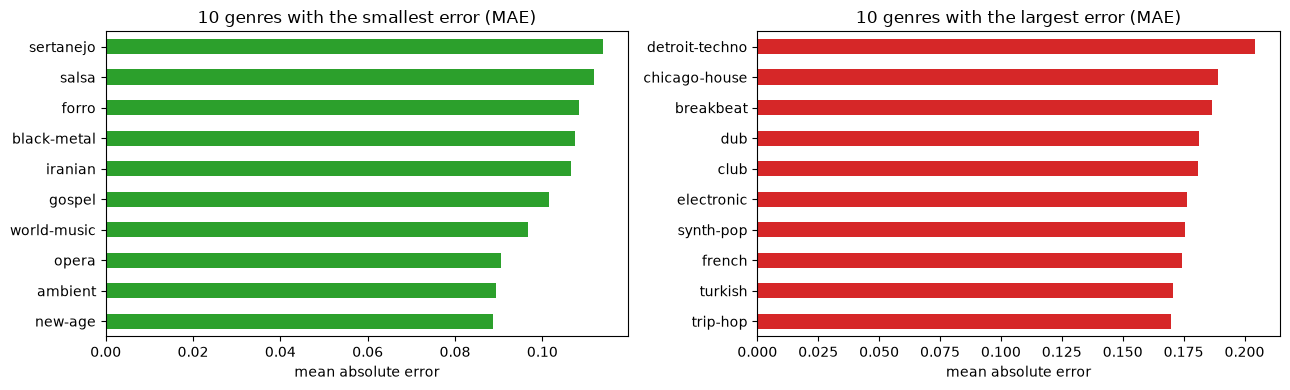

In [25]:
mae_by_genre = resid.abs().groupby(X["track_genre"]).mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mae_by_genre.head(10).plot.barh(ax=axes[0], color="tab:green")
axes[0].set_title("10 genres with the smallest error (MAE)")
mae_by_genre.tail(10).plot.barh(ax=axes[1], color="tab:red")
axes[1].set_title("10 genres with the largest error (MAE)")
for ax in axes:
    ax.set_xlabel("mean absolute error")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

The worst genres are mostly electronic dance genres, which is the same problem as above. The best ones are quiet genres with consistently low valence, like ambient and new-age.

## 7. Test set results

We train each final model on the whole training set and score it once on the test set.

In [26]:
test_df = pd.read_csv("test_clean.csv")
X_test = test_df.drop(columns=["valence"])
X_test["explicit"] = X_test["explicit"].astype(int)
y_test = test_df["valence"]
y_test_sad = (y_test < SAD_CUTOFF).astype(int)
print("Test set:", X_test.shape, f"| sad share {y_test_sad.mean():.1%}")

final_reg = {
    "Baseline: predict mean": DummyRegressor(strategy="mean"),
    "Linear regression (audio + genre)": lin_full,
    "Ridge (tuned)": ridge_grid.best_estimator_,
    "Ridge + degree-2 polynomial (tuned)": ridge_poly_grid.best_estimator_,
}
test_reg = []
for name, model in final_reg.items():
    pred = model.fit(X, y).predict(X_test)
    test_reg.append({"model": name,
                     "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                     "test MAE": mean_absolute_error(y_test, pred),
                     "test R2": r2_score(y_test, pred)})
pd.DataFrame(test_reg).round(4)

Test set: (15785, 14) | sad share 31.0%


,model,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2592,0.2213,-0.0002
1,Linear regression (audio + genre),0.1850,0.1488,0.4905
2,Ridge (tuned),0.1849,0.1488,0.4906
3,Ridge + degree-2 polynomial (tuned),0.1795,0.1435,0.5201


In [27]:
final_clf = best_logreg.fit(X, y_sad)
test_proba = final_clf.predict_proba(X_test)[:, 1]
test_clf = []
for t in [0.5, best_t]:
    pred = (test_proba >= t).astype(int)
    test_clf.append({"threshold": t, "model": f"Logistic regression (threshold {t:.2f})",
                     "test F1": f1_score(y_test_sad, pred),
                     "test ROC-AUC": roc_auc_score(y_test_sad, test_proba),
                     "test accuracy": (pred == y_test_sad).mean()})
base_pred = np.zeros_like(y_test_sad)
test_clf.insert(0, {"model": "Baseline: always 'not sad'", "test F1": f1_score(y_test_sad, base_pred),
                    "test ROC-AUC": 0.5, "test accuracy": (base_pred == y_test_sad).mean()})
pd.DataFrame(test_clf).drop(columns="threshold").round(4)

,model,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.0000,0.5000,0.6903
1,Logistic regression (threshold 0.50),0.6765,0.8526,0.7713
2,Logistic regression (threshold 0.52),0.6776,0.8526,0.7769


The test scores are close to the cross-validation scores, so the models aren't overfitting.

## 8. Summary

- The best regression model is ridge with polynomial features (test R² 0.52, RMSE 0.18, compared to 0.26 for the baseline).
- Logistic regression gets a test F1 of 0.68 and ROC-AUC of 0.85.
- Genre helps a lot. Ridge and lasso don't help over plain linear regression. Polynomial features help a little.
- Balanced class weights and a lower threshold give the same F1.
- Minor key doesn't make songs much sadder. Low energy does on average. Acousticness has little effect.
- The biggest errors are on high-energy songs with low valence, especially in electronic genres. Models that can learn interactions, like trees, should do better on these.

### Results for the shared sheet

In [28]:
reg_table = pd.DataFrame(reg_results).merge(pd.DataFrame(test_reg), on="model", how="left")
clf_table = pd.DataFrame(clf_results)
test_by_t = {r["threshold"]: r for r in test_clf if "threshold" in r}
for col in ["test F1", "test ROC-AUC", "test accuracy"]:
    clf_table[col] = [test_by_t[r["threshold"]][col] if r["model"].startswith("Logistic") else np.nan
                      for _, r in clf_table.iterrows()]
reg_table.to_csv("results_linear_regression.csv", index=False)
clf_table.to_csv("results_linear_classification.csv", index=False)
print("Saved results_linear_regression.csv and results_linear_classification.csv")
display(reg_table.round(4))
display(clf_table.round(4))

Saved results_linear_regression.csv and results_linear_classification.csv


,model,RMSE,RMSE_std,MAE,R2,notes,test RMSE,test MAE,test R2
0,Baseline: predict mean,0.2621,0.0008,0.2240,-0.0000,,0.2592,0.2213,-0.0002
1,Linear regression (audio only),0.2070,0.0016,0.1689,0.3762,no genre,NaN,NaN,NaN
2,Linear regression (audio + genre),0.1842,0.0009,0.1480,0.5060,one-hot genre,0.1850,0.1488,0.4905
3,Ridge (tuned),0.1842,0.0009,0.1481,0.5060,alpha=3.16,0.1849,0.1488,0.4906
4,Lasso (tuned),0.1842,0.0009,0.1481,0.5061,alpha=1e-05,NaN,NaN,NaN
5,Ridge + degree-2 polynomial (tuned),0.1792,0.0009,0.1432,0.5327,alpha=3.16,0.1795,0.1435,0.5201


,model,threshold,F1,ROC_AUC,accuracy,notes,test F1,test ROC-AUC,test accuracy
0,Baseline: always 'not sad',0.50,0.0000,0.5000,0.6902,,NaN,NaN,NaN
1,"Logistic regression (tuned, threshold 0.5)",0.50,0.6882,0.8626,0.7809,"C=1, class_weight=balanced",0.6765,0.8526,0.7713
2,"Logistic regression (tuned, threshold 0.52)",0.52,0.6888,0.8626,0.7860,"C=1, class_weight=balanced",0.6776,0.8526,0.7769
